<a href="https://colab.research.google.com/github/yolacin/LocalDispersion/blob/main/ToGitHub_MetroData_KNN_V_CQR_SCPI_comparisons_Extended_simplified.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# -*- coding: utf-8 -*-
"""
Metro_Data_KNN-V_CQR_SPCI_Augmented_Comparisons.py
Adapted end-to-end for hourly traffic data.
"""

!pip install scikit-learn==1.5.2 mapie==0.8.6 pmdarima

import pandas as pd
import numpy as np
import random
import warnings
import matplotlib.pyplot as plt
from datetime import date, timedelta, datetime

from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error as MAE, cohen_kappa_score

from mapie.quantile_regression import MapieQuantileRegressor
from pmdarima import auto_arima

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.optimizers import Adam
from statsmodels.tsa.arima.model import ARIMA
from google.colab import drive

warnings.filterwarnings('ignore')

# Set random seeds for 100% reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [ ]:
# ==============================================================================
# 1. DATA IMPORTING & SETUP
# ==============================================================================
drive.mount('/content/drive')

path_to_file = "path_to_file" # path to data.
metro_data = pd.read_csv(path_to_file)
metro_data.columns = ["date_time", "traffic_volume"]

# Optimal hyperparameters provided by prior grid search
short_w, short_k = 4, 10
long_w, long_k = 13, 5

# Ensure chronologically sorted data
metro_data['date_time'] = pd.to_datetime(metro_data['date_time'])
metro_data = metro_data.sort_values('date_time').reset_index(drop=True)

Mounted at /content/drive


In [ ]:
# ==============================================================================
# 2. UTILITY FUNCTIONS
# ==============================================================================
def create_train_test_data_by_ratio(df, window_size, test_ratio, time_series_col_name):
    total_rows = len(df)
    test_rows = int(total_rows * test_ratio)

    df_train = df.iloc[:-test_rows]
    df_test = df.iloc[-test_rows:]

    print("train beginning date-time", df_train.iloc[0]['date_time'])
    print("train end date-time:", df_train.iloc[-1]['date_time'])

    print("test beginning date-time:", df_test.iloc[0]['date_time'])
    print("test end date-time:", df_test.iloc[-1]['date_time'])

    df_train_values = df_train[time_series_col_name].values
    df_test_values = df_test[time_series_col_name].values

    train_data_as_traj = np.zeros((len(df_train) - window_size, window_size + 1), dtype="float32")
    test_data_as_traj = np.zeros((len(df_test) - window_size, window_size + 1), dtype="float32")

    for i in range(window_size + 1):
        train_data_as_traj[:, i] = df_train_values[i : len(df_train_values) + i - window_size]
        test_data_as_traj[:, i] = df_test_values[i : len(df_test_values) + i - window_size]

    return train_data_as_traj[:, :-1], train_data_as_traj[:, -1], test_data_as_traj[:, :-1], test_data_as_traj[:, -1]

def knn_test_predictions(X_train, y_train, X_test, n_neighbors=5, feature_weights=None):
    X_train, X_test, y_train = np.asarray(X_train), np.asarray(X_test), np.asarray(y_train)
    feature_weights = np.ones(X_train.shape[1]) if feature_weights is None else np.asarray(feature_weights)
    sqrt_w = np.sqrt(feature_weights)

    knn = NearestNeighbors(n_neighbors=n_neighbors, metric='euclidean', algorithm='auto')
    knn.fit(X_train * sqrt_w)
    distances, indices = knn.kneighbors(X_test * sqrt_w)

    neighbor_targets = y_train[indices]
    return neighbor_targets.mean(axis=1), indices, neighbor_targets, distances

def knn_train_predictions(X_train, y_train, n_neighbors=5, feature_weights=None):
    X_train, y_train = np.asarray(X_train), np.asarray(y_train)
    feature_weights = np.ones(X_train.shape[1]) if feature_weights is None else np.asarray(feature_weights)
    sqrt_w = np.sqrt(feature_weights)

    knn = NearestNeighbors(n_neighbors=n_neighbors+1, metric='euclidean')
    knn.fit(X_train * sqrt_w)
    distances, indices = knn.kneighbors(X_train * sqrt_w)

    distances, indices = distances[:, 1:], indices[:, 1:]
    neighbor_targets = y_train[indices]
    return neighbor_targets.mean(axis=1), indices, neighbor_targets, distances


In [ ]:
# ==============================================================================
# 3. DATA PREPARATION & SPLITTING
# ==============================================================================
window_size = 168  # 1 week of hourly history
test_ratio = 0.18

X_train_val, y_train_val, X_test, y_test = create_train_test_data_by_ratio(metro_data, window_size, test_ratio, "traffic_volume")


train beginning date-time 2016-05-01 00:00:00
train end date-time: 2018-04-25 01:00:00
test beginning date-time: 2018-04-25 02:00:00
test end date-time: 2018-09-30 23:00:00


In [ ]:
# ==============================================================================
# 4. HEURISTIC 1: PROPOSED KNN-VARIANCE (KNNC2) & ROLLING VARIANCE BASELINE
# ==============================================================================
f_weights_short = np.array([j+1 for j in range(X_train_val[:,-short_w:].shape[1])])
y_train_val_knn_1_pred, nn_TV_indices_1, _, _ = knn_train_predictions(X_train_val[:,-short_w:], y_train_val, n_neighbors=short_k, feature_weights=f_weights_short)

f_weights_long = np.array([j+1 for j in range(X_train_val[:,-long_w:].shape[1])])
y_train_val_knn_2_pred, nn_TV_indices_2, _, _ = knn_train_predictions(X_train_val[:,-long_w:], y_train_val, n_neighbors=long_k, feature_weights=f_weights_long)
nn_ALL_TV_indicies = np.concatenate((nn_TV_indices_1, nn_TV_indices_2), axis=1)

y_test_knn_1_pred, nn_TST_indices_1, _, _ = knn_test_predictions(X_train_val[:,-short_w:], y_train_val, X_test[:,-short_w:], n_neighbors=short_k, feature_weights=f_weights_short)
y_test_knn_2_pred, nn_TST_indices_2, _, _ = knn_test_predictions(X_train_val[:,-long_w:], y_train_val, X_test[:,-long_w:], n_neighbors=long_k, feature_weights=f_weights_long)
nn_ALL_TST_indicies = np.concatenate((nn_TST_indices_1, nn_TST_indices_2), axis=1)

# A. Proposed Dual-Scale KNN Feature-Space Variance
VarFlowKNNC2Test = np.array([np.var(y_train_val[nn_ALL_TST_indicies[i].astype(int)]) for i in range(len(y_test))])

# B. Baseline Chronological Rolling Variance (Looking back short_w hours in the actual test timeline)
# We append the end of training targets to align chronological windows smoothly at test index 0
combined_targets_for_roll = np.concatenate([y_train_val[-short_w:], y_test])
rolling_var_series = pd.Series(combined_targets_for_roll).rolling(window=short_w).var().fillna(0).values
VarRollingBaselineTest = rolling_var_series[short_w:] # Extract exactly the test alignment size

In [ ]:
# ==============================================================================
# 5. FEATURE ENGINEERING FOR POINT FORECASTING
# ==============================================================================
lag_indices = [0, 1, 2, 3, 4, -26, -25, -24, -3, -2, -1]
X_train_val_lag_features = X_train_val[:, lag_indices]
X_test_lag_features = X_test[:, lag_indices]


RUNNING BASE MATRIX EXPERIMENT FOR STATION: METRO DATA

[1/6] Training CQR (Global Tree-based UQ)...

[2/6] Training SCPI Proxy (Sequential Residual Forecaster)...

[3/6] Training DNN Forecaster...

[4/6] Training LSTM Forecaster...

[5/6] Training ARIMA Forecaster...

[6/6] Generating Curves for Base Forecasters...


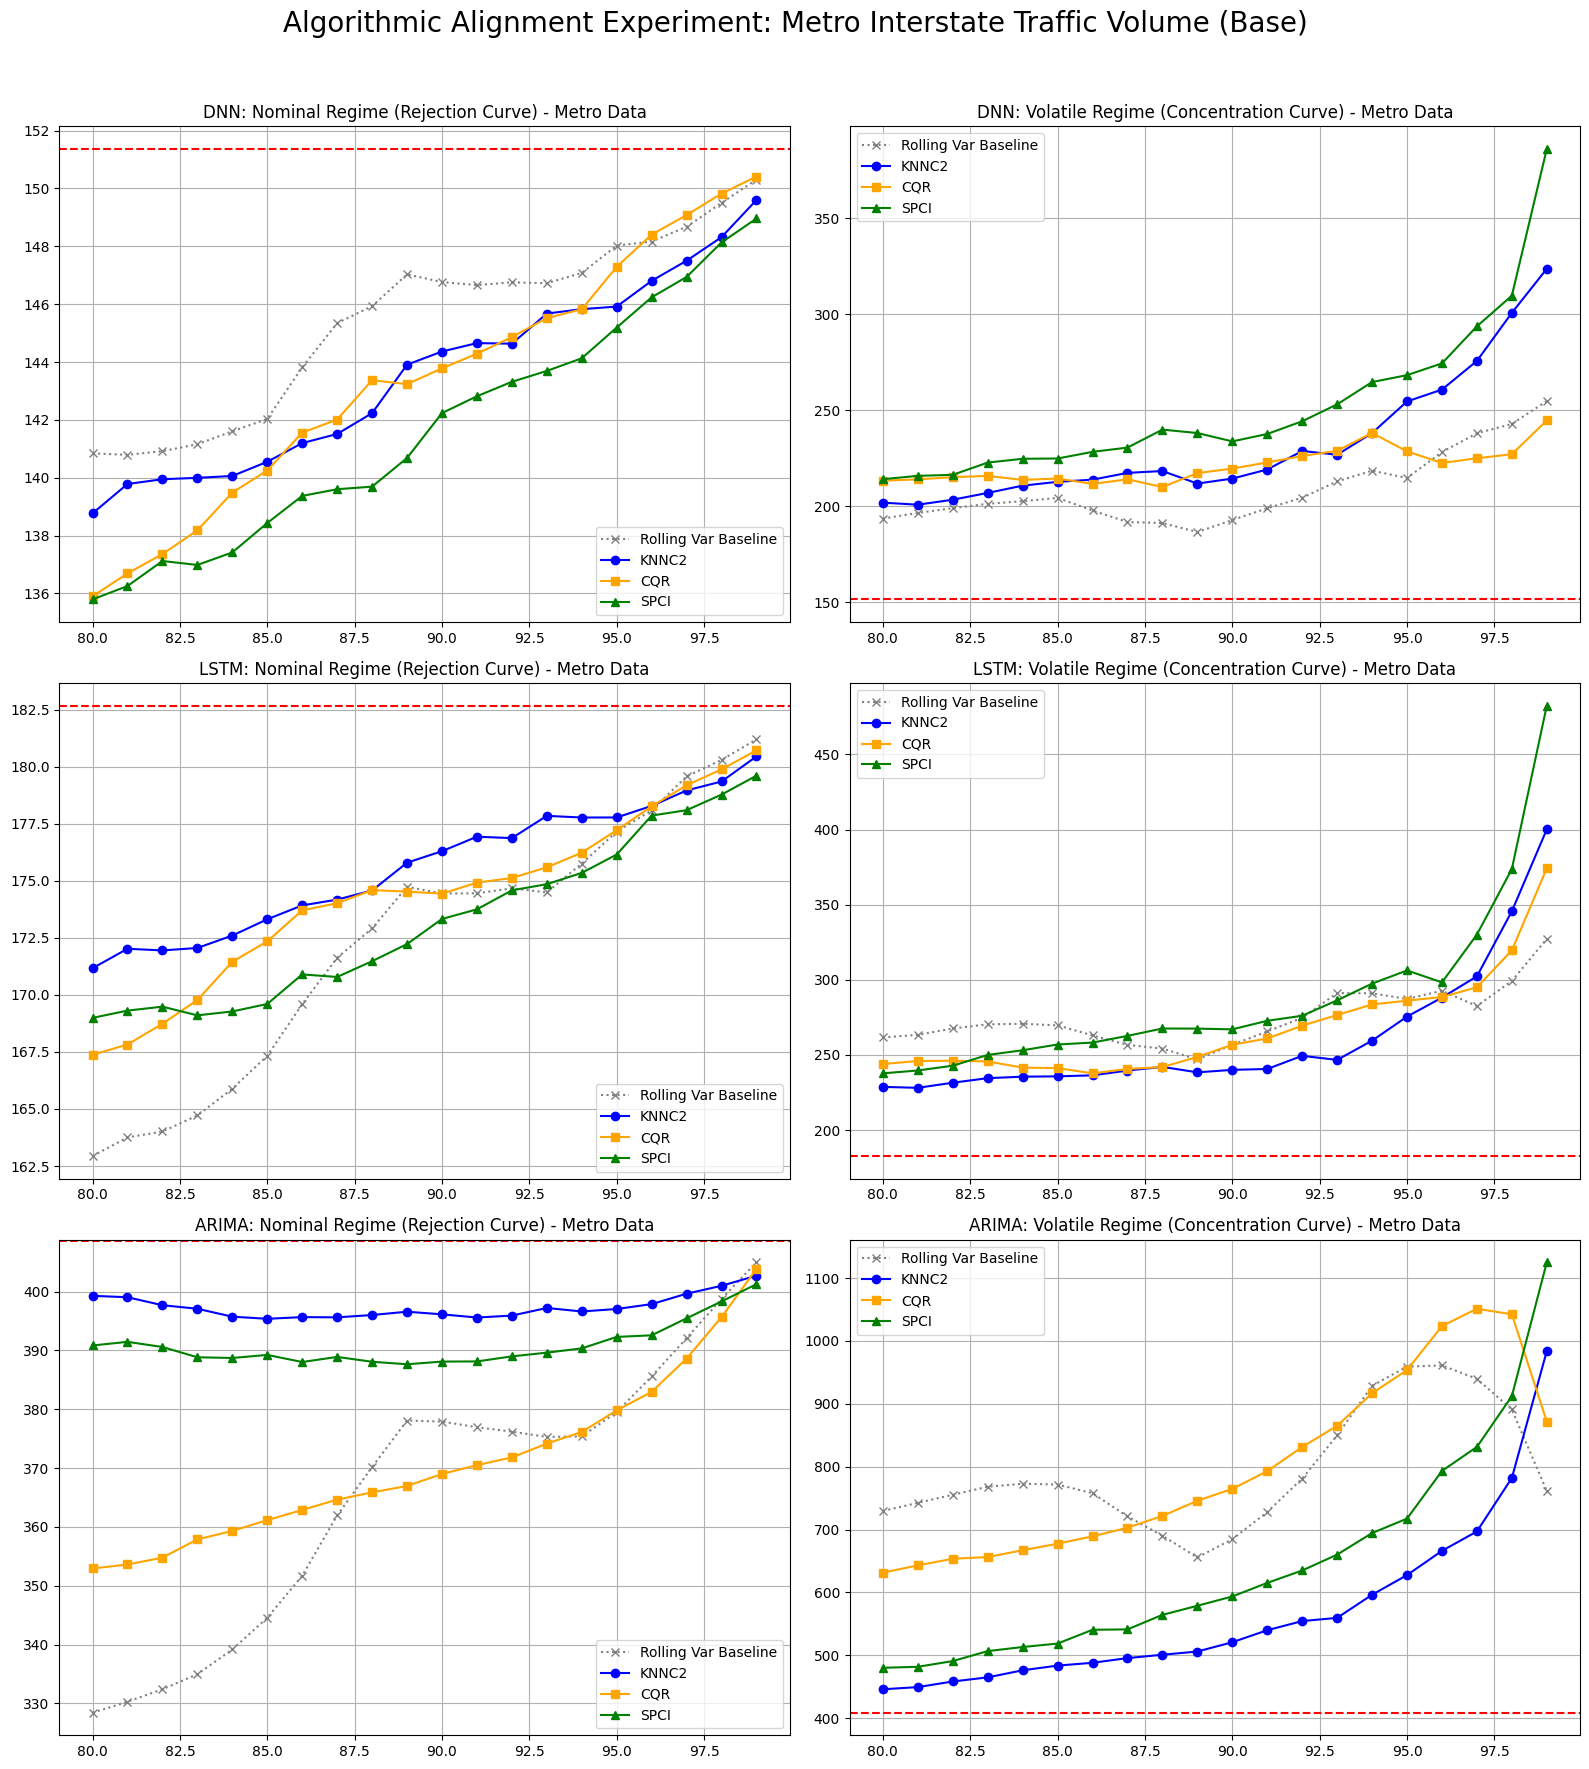

In [ ]:
# ==============================================================================
# 6. EXPERIMENT A: BASE FORECASTERS & BASE UQ ALIGNMENT
# ==============================================================================
print(f"\n{'='*50}\nRUNNING BASE MATRIX EXPERIMENT FOR STATION: METRO DATA\n{'='*50}")

print("\n[1/6] Training CQR (Global Tree-based UQ)...")
cqr_estimator = GradientBoostingRegressor(loss='quantile', random_state=42)
mapie_cqr = MapieQuantileRegressor(estimator=cqr_estimator, cv="split", alpha=0.1)
mapie_cqr.fit(X_train_val_lag_features, y_train_val)
_, y_pis_cqr = mapie_cqr.predict(X_test_lag_features)
interval_widths_cqr = y_pis_cqr[:, 1, 0] - y_pis_cqr[:, 0, 0]

print("\n[2/6] Training SCPI Proxy (Sequential Residual Forecaster)...")
spci_base = GradientBoostingRegressor(random_state=42)
oof_preds = cross_val_predict(spci_base, X_train_val_lag_features, y_train_val, cv=5)
oof_residuals = np.abs(y_train_val - oof_preds)
spci_uq_model = GradientBoostingRegressor(random_state=42)
spci_uq_model.fit(X_train_val_lag_features, oof_residuals)
interval_widths_spci = spci_uq_model.predict(X_test_lag_features)

predictions = {}

print("\n[3/6] Training DNN Forecaster...")
model_dnn = Sequential([
    Input(shape=(X_train_val_lag_features.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])
model_dnn.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model_dnn.fit(X_train_val_lag_features, y_train_val, epochs=30, batch_size=32, verbose=0)
predictions['DNN'] = model_dnn.predict(X_test_lag_features, verbose=0).flatten()

print("\n[4/6] Training LSTM Forecaster...")
X_train_lstm = X_train_val[:, -24:].reshape((X_train_val[:, -24:].shape[0], 1, 24))
X_test_lstm = X_test[:, -24:].reshape((X_test[:, -24:].shape[0], 1, 24))

model_lstm = Sequential([
    Input(shape=(1, 24)),
    LSTM(64, activation='relu'),
    Dense(1)
])
model_lstm.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model_lstm.fit(X_train_lstm, y_train_val, epochs=30, batch_size=32, verbose=0)
predictions['LSTM'] = model_lstm.predict(X_test_lstm, verbose=0).flatten()

print("\n[5/6] Training ARIMA Forecaster...")
try:
    auto_model = auto_arima(y_train_val, start_p=1, start_q=1, max_p=3, max_q=3, seasonal=False, trace=False)
    arima_model = ARIMA(y_train_val, order=auto_model.order).fit()
    arima_res = arima_model.apply(y_test)
    predictions['ARIMA'] = arima_res.fittedvalues
except Exception as e:
    predictions['ARIMA'] = X_test[:, -1]

# --- Generate Curves for Base Experiment ---
print("\n[6/6] Generating Curves for Base Forecasters...")
percentiles = [80 + k for k in range(20)]
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Algorithmic Alignment Experiment: Metro Interstate Traffic Volume (Base)', fontsize=20, y=0.98)
models_to_test = ['DNN', 'LSTM', 'ARIMA']

for i, model_name in enumerate(models_to_test):
    y_pred = predictions[model_name]
    baseline_mae = MAE(y_test, y_pred)
    stable_knn, stable_cqr, stable_spci = [], [], []
    unstable_knn, unstable_cqr, unstable_spci, stable_roll, unstable_roll = [], [], [], [], []

    for p in percentiles:
      thresh_knn = np.percentile(VarFlowKNNC2Test, p)
      thresh_cqr = np.percentile(interval_widths_cqr, p)
      thresh_spci = np.percentile(interval_widths_spci, p)
      thresh_roll = np.percentile(VarRollingBaselineTest, p) # New threshold

      mask_s_knn = VarFlowKNNC2Test <= thresh_knn
      mask_s_cqr = interval_widths_cqr <= thresh_cqr
      mask_s_spci = interval_widths_spci <= thresh_spci
      mask_s_roll = VarRollingBaselineTest <= thresh_roll # New mask

      mask_u_knn = VarFlowKNNC2Test > thresh_knn
      mask_u_cqr = interval_widths_cqr > thresh_cqr
      mask_u_spci = interval_widths_spci > thresh_spci
      mask_u_roll = VarRollingBaselineTest > thresh_roll # New mask

      stable_knn.append(MAE(y_test[mask_s_knn], y_pred[mask_s_knn]))
      stable_cqr.append(MAE(y_test[mask_s_cqr], y_pred[mask_s_cqr]))
      stable_spci.append(MAE(y_test[mask_s_spci], y_pred[mask_s_spci]))
      stable_roll.append(MAE(y_test[mask_s_roll], y_pred[mask_s_roll])) # Track it

      unstable_knn.append(MAE(y_test[mask_u_knn], y_pred[mask_u_knn]) if mask_u_knn.sum() > 0 else np.nan)
      unstable_cqr.append(MAE(y_test[mask_u_cqr], y_pred[mask_u_cqr]) if mask_u_cqr.sum() > 0 else np.nan)
      unstable_spci.append(MAE(y_test[mask_u_spci], y_pred[mask_u_spci]) if mask_u_spci.sum() > 0 else np.nan)
      unstable_roll.append(MAE(y_test[mask_u_roll], y_pred[mask_u_roll]) if mask_u_roll.sum() > 0 else np.nan) # Track it

# Plot the new baseline line (e.g., dashed gray line) alongside KNNC2, CQR, and SPCI:
    axes[i, 0].plot(percentiles, stable_roll, marker='x', label='Rolling Var Baseline', color='gray', linestyle=':')
    axes[i, 1].plot(percentiles, unstable_roll, marker='x', label='Rolling Var Baseline', color='gray', linestyle=':')

    axes[i, 0].plot(percentiles, stable_knn, marker='o', label='KNNC2', color='blue')
    axes[i, 0].plot(percentiles, stable_cqr, marker='s', label='CQR', color='orange')
    axes[i, 0].plot(percentiles, stable_spci, marker='^', label='SPCI', color='green')
    axes[i, 0].axhline(y=baseline_mae, color='red', linestyle='--')
    axes[i, 0].set_title(f'{model_name}: Nominal Regime (Rejection Curve) - Metro Data')
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    axes[i, 1].plot(percentiles, unstable_knn, marker='o', label='KNNC2', color='blue')
    axes[i, 1].plot(percentiles, unstable_cqr, marker='s', label='CQR', color='orange')
    axes[i, 1].plot(percentiles, unstable_spci, marker='^', label='SPCI', color='green')
    axes[i, 1].axhline(y=baseline_mae, color='red', linestyle='--')
    axes[i, 1].set_title(f'{model_name}: Volatile Regime (Concentration Curve) - Metro Data')
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
path_to_save_fig = "path_to_save_fig" # path to save results.
figure_file_name = "WithOutKNNC2FeaturesMetroData.png"
plt.savefig(path_to_save_fig + figure_file_name, dpi=300)
plt.show()

In [ ]:
# ==============================================================================
# 7. EXPERIMENT B: CASE 1 AUGMENTED FEATURES EXPERIMENT
# ==============================================================================
print(f"\n{'='*50}\nRUNNING AUGMENTED FEATURE EXPERIMENT FOR STATION: METRO DATA\n{'='*50}")

knn_features_train = np.column_stack((y_train_val_knn_1_pred, y_train_val_knn_2_pred))
knn_features_test = np.column_stack((y_test_knn_1_pred, y_test_knn_2_pred))

X_train_val_augmented = np.hstack((X_train_val_lag_features, knn_features_train))
X_test_augmented = np.hstack((X_test_lag_features, knn_features_test))

X_train_lstm_augmented_2d = np.hstack((X_train_val[:, -24:], knn_features_train))
X_test_lstm_augmented_2d = np.hstack((X_test[:, -24:], knn_features_test))

X_train_lstm_aug = X_train_lstm_augmented_2d.reshape((X_train_lstm_augmented_2d.shape[0], 1, X_train_lstm_augmented_2d.shape[1]))
X_test_lstm_aug = X_test_lstm_augmented_2d.reshape((X_test_lstm_augmented_2d.shape[0], 1, X_test_lstm_augmented_2d.shape[1]))

print("\n[1/5] Training Augmented CQR...")
mapie_cqr_aug = MapieQuantileRegressor(estimator=cqr_estimator, cv="split", alpha=0.1)
mapie_cqr_aug.fit(X_train_val_augmented, y_train_val)
_, y_pis_cqr_aug = mapie_cqr_aug.predict(X_test_augmented)
interval_widths_cqr_aug = y_pis_cqr_aug[:, 1, 0] - y_pis_cqr_aug[:, 0, 0]

print("\n[2/5] Training Augmented SCPI Proxy...")
oof_preds_aug = cross_val_predict(spci_base, X_train_val_augmented, y_train_val, cv=5)
oof_residuals_aug = np.abs(y_train_val - oof_preds_aug)
spci_uq_model_aug = GradientBoostingRegressor(random_state=42)
spci_uq_model_aug.fit(X_train_val_augmented, oof_residuals_aug)
interval_widths_spci_aug = spci_uq_model_aug.predict(X_test_augmented)

predictions_aug = {}

print("\n[3/5] Training Augmented DNN...")
model_dnn_aug = Sequential([
    Input(shape=(X_train_val_augmented.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])
model_dnn_aug.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model_dnn_aug.fit(X_train_val_augmented, y_train_val, epochs=30, batch_size=32, verbose=0)
predictions_aug['DNN'] = model_dnn_aug.predict(X_test_augmented, verbose=0).flatten()

print("\n[4/5] Training Augmented LSTM...")
model_lstm_aug = Sequential([
    Input(shape=(1, X_train_lstm_augmented_2d.shape[1])),
    LSTM(64, activation='relu'),
    Dense(1)
])
model_lstm_aug.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model_lstm_aug.fit(X_train_lstm_aug, y_train_val, epochs=30, batch_size=32, verbose=0)
predictions_aug['LSTM'] = model_lstm_aug.predict(X_test_lstm_aug, verbose=0).flatten()

print("\n[5/5] Training ARIMAX Forecaster...")
try:
    auto_model_aug = auto_arima(y_train_val, X=knn_features_train, start_p=1, start_q=1, max_p=3, max_q=3, seasonal=False, trace=False)
    arima_model_aug = ARIMA(y_train_val, exog=knn_features_train, order=auto_model_aug.order).fit()
    arima_res_aug = arima_model_aug.apply(y_test, exog=knn_features_test)
    predictions_aug['ARIMAX'] = arima_res_aug.fittedvalues
except Exception as e:
    predictions_aug['ARIMAX'] = knn_features_test[:, 0]




RUNNING AUGMENTED FEATURE EXPERIMENT FOR STATION: METRO DATA

[1/5] Training Augmented CQR...

[2/5] Training Augmented SCPI Proxy...

[3/5] Training Augmented DNN...

[4/5] Training Augmented LSTM...

[5/5] Training ARIMAX Forecaster...


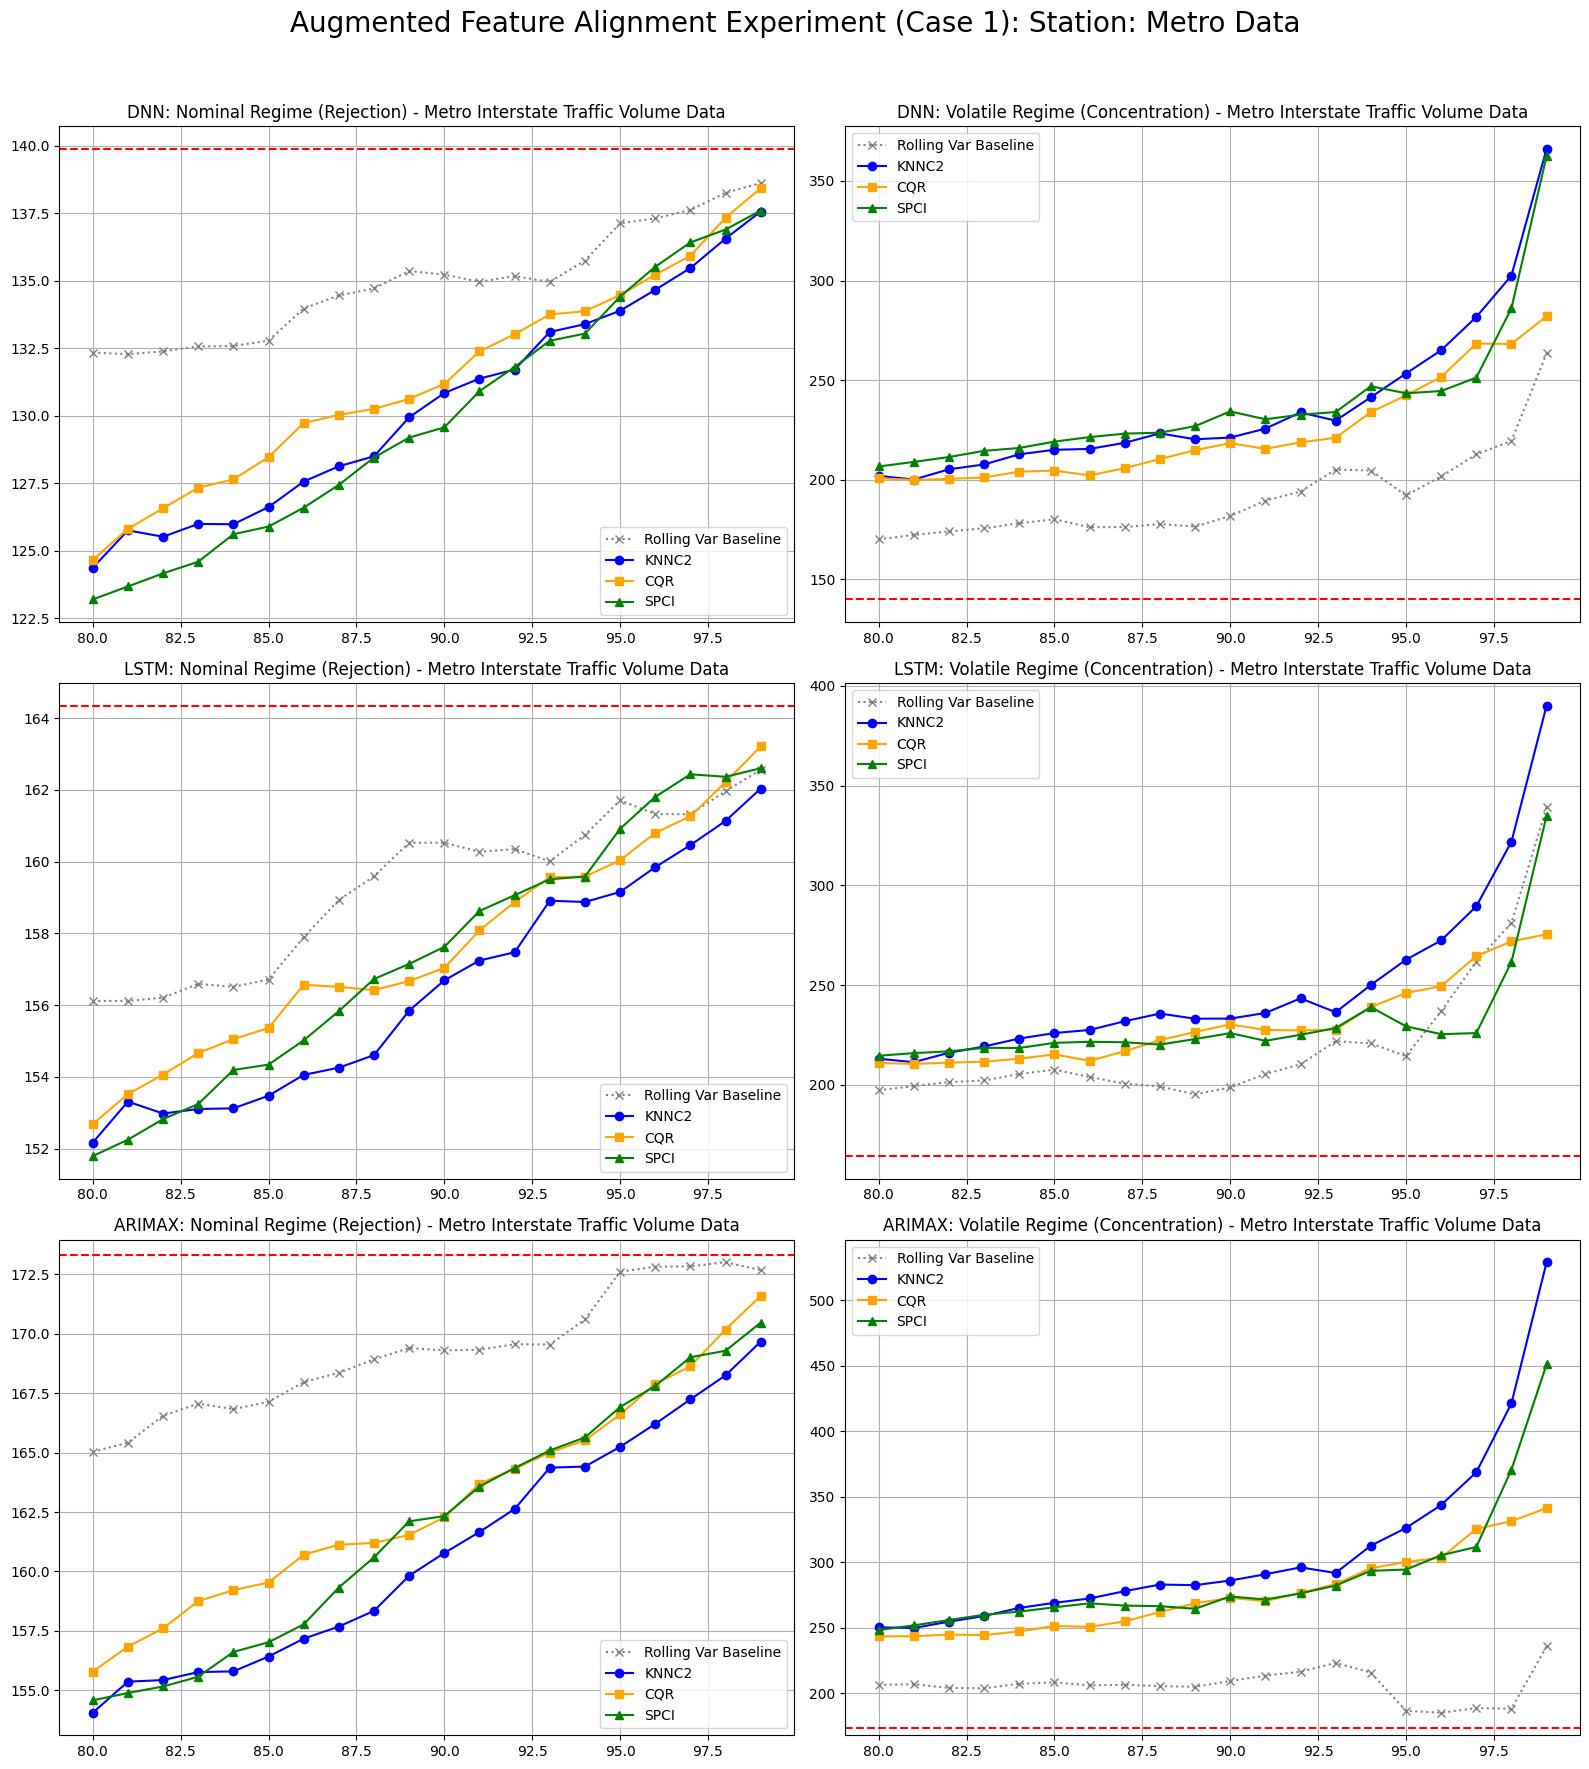


Execution Complete! All graphs generated successfully.


In [ ]:
# --- Generate Curves for Case 1 Augmented Experiment ---
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Augmented Feature Alignment Experiment (Case 1): Station: Metro Data', fontsize=20, y=0.98)
models_to_test_aug = ['DNN', 'LSTM', 'ARIMAX']

for i, model_name in enumerate(models_to_test_aug):
    y_pred = predictions_aug[model_name]
    baseline_mae = MAE(y_test, y_pred)
    stable_knn, stable_cqr, stable_spci = [], [], []
    unstable_knn, unstable_cqr, unstable_spci, stable_roll, unstable_roll = [], [], [], [], []

    for p in percentiles:
      thresh_knn = np.percentile(VarFlowKNNC2Test, p)
      thresh_cqr = np.percentile(interval_widths_cqr_aug, p)
      thresh_spci = np.percentile(interval_widths_spci_aug, p)
      thresh_roll = np.percentile(VarRollingBaselineTest, p) # New threshold

      mask_s_knn = VarFlowKNNC2Test <= thresh_knn
      mask_s_cqr = interval_widths_cqr_aug <= thresh_cqr
      mask_s_spci = interval_widths_spci_aug <= thresh_spci
      mask_s_roll = VarRollingBaselineTest <= thresh_roll # New mask

      mask_u_knn = VarFlowKNNC2Test > thresh_knn
      mask_u_cqr = interval_widths_cqr_aug > thresh_cqr
      mask_u_spci = interval_widths_spci_aug > thresh_spci
      mask_u_roll = VarRollingBaselineTest > thresh_roll # New mask

      stable_knn.append(MAE(y_test[mask_s_knn], y_pred[mask_s_knn]))
      stable_cqr.append(MAE(y_test[mask_s_cqr], y_pred[mask_s_cqr]))
      stable_spci.append(MAE(y_test[mask_s_spci], y_pred[mask_s_spci]))
      stable_roll.append(MAE(y_test[mask_s_roll], y_pred[mask_s_roll])) # Track it

      unstable_knn.append(MAE(y_test[mask_u_knn], y_pred[mask_u_knn]) if mask_u_knn.sum() > 0 else np.nan)
      unstable_cqr.append(MAE(y_test[mask_u_cqr], y_pred[mask_u_cqr]) if mask_u_cqr.sum() > 0 else np.nan)
      unstable_spci.append(MAE(y_test[mask_u_spci], y_pred[mask_u_spci]) if mask_u_spci.sum() > 0 else np.nan)
      unstable_roll.append(MAE(y_test[mask_u_roll], y_pred[mask_u_roll]) if mask_u_roll.sum() > 0 else np.nan) # Track it

# Plot the new baseline line (e.g., dashed gray line) alongside KNNC2, CQR, and SPCI:
    axes[i, 0].plot(percentiles, stable_roll, marker='x', label='Rolling Var Baseline', color='gray', linestyle=':')
    axes[i, 1].plot(percentiles, unstable_roll, marker='x', label='Rolling Var Baseline', color='gray', linestyle=':')

    axes[i, 0].plot(percentiles, stable_knn, marker='o', label='KNNC2', color='blue')
    axes[i, 0].plot(percentiles, stable_cqr, marker='s', label='CQR', color='orange')
    axes[i, 0].plot(percentiles, stable_spci, marker='^', label='SPCI', color='green')
    axes[i, 0].axhline(y=baseline_mae, color='red', linestyle='--')
    axes[i, 0].set_title(f'{model_name}: Nominal Regime (Rejection) - Metro Interstate Traffic Volume Data')
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    axes[i, 1].plot(percentiles, unstable_knn, marker='o', label='KNNC2', color='blue')
    axes[i, 1].plot(percentiles, unstable_cqr, marker='s', label='CQR', color='orange')
    axes[i, 1].plot(percentiles, unstable_spci, marker='^', label='SPCI', color='green')
    axes[i, 1].axhline(y=baseline_mae, color='red', linestyle='--')
    axes[i, 1].set_title(f'{model_name}: Volatile Regime (Concentration) - Metro Interstate Traffic Volume Data')
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
path_to_save_fig = "path_to_save_fig" # path to save results.
figure_file_name = "WithKNNC2FeaturesMetroData.png"
plt.savefig(path_to_save_fig + figure_file_name, dpi=300)
plt.show()
print("\nExecution Complete! All graphs generated successfully.")


RUNNING RANK-BASED PREDICTIVE ACCURACY TEST


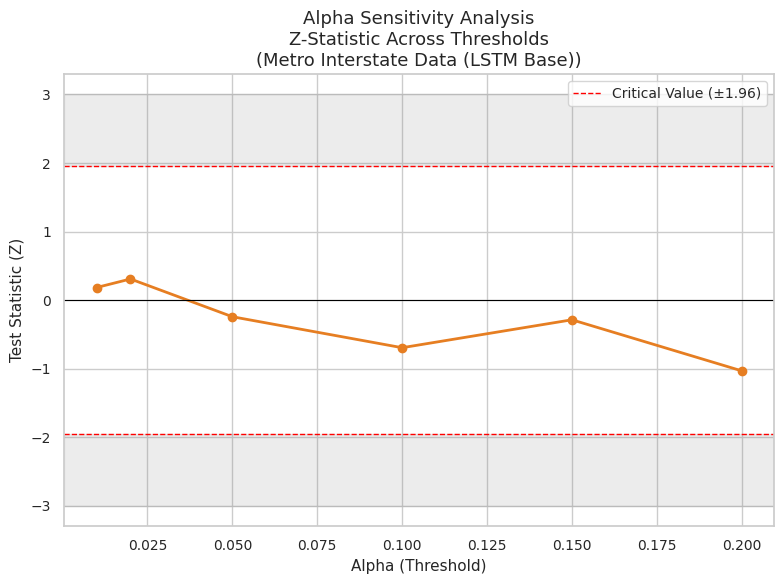

Data successfully exported to: /content/drive/My Drive/PEMS_2022_24_TRAFFIC_FLOW_PREDICTION/METRO/MetroDataResultsAfterReload/Station_Metro_Data_Complete_Results.pkl


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import timedelta
import pickle
import os

# ==============================================================================
# 8. TASK 14: RANK-BASED PREDICTIVE ACCURACY TEST
# ==============================================================================

def compute_loss_differential_results(
    timestamps, y_true, y_pred, disp_m1, disp_m2,
    alphas=[0.01, 0.02, 0.05, 0.10, 0.15, 0.20],
    hac_lags=None,
    metadata=None
):
    loss_t = np.abs(y_true - y_pred)
    T = len(loss_t)

    if hac_lags is None:
        hac_lags = int(4 * (T / 100)**(2/9))

    z_stats_list, p_vals_list, d_bar_list, hac_se_list = [], [], [], []
    fixed_alpha_05_data = {}

    for alpha in alphas:
        thresh_m1 = np.quantile(disp_m1, 1 - alpha)
        thresh_m2 = np.quantile(disp_m2, 1 - alpha)

        A_t_1 = (disp_m1 >= thresh_m1).astype(int)
        A_t_2 = (disp_m2 >= thresh_m2).astype(int)

        d_t = loss_t * (A_t_1 - A_t_2)
        d_bar = np.mean(d_t)

        gamma_0 = np.mean((d_t - d_bar)**2)
        hac_var = gamma_0
        for j in range(1, hac_lags + 1):
            gamma_j = np.mean((d_t[j:] - d_bar) * (d_t[:-j] - d_bar))
            weight = 1 - (j / (hac_lags + 1))
            hac_var += 2 * weight * gamma_j

        hac_se = np.sqrt(hac_var / T) if hac_var > 0 else 1e-9
        z_stat = d_bar / hac_se
        p_val = 2 * (1 - norm.cdf(abs(z_stat)))

        z_stats_list.append(z_stat)
        p_vals_list.append(p_val)
        d_bar_list.append(d_bar)
        hac_se_list.append(hac_se)

        if np.isclose(alpha, 0.05):
            mean_loss_u1 = np.mean(loss_t[A_t_1 == 1]) if sum(A_t_1) > 0 else 0
            mean_loss_u2 = np.mean(loss_t[A_t_2 == 1]) if sum(A_t_2) > 0 else 0
            fixed_alpha_05_data = {
                'd_t': d_t,
                'cum_d_t': np.cumsum(d_t),
                'loss_m1': mean_loss_u1,
                'loss_m2': mean_loss_u2,
            }

    if not fixed_alpha_05_data and len(alphas) > 0:
        fixed_alpha_05_data = {
            'd_t': d_t, 'cum_d_t': np.cumsum(d_t), 'loss_m1': 0, 'loss_m2': 0
        }

    if metadata is None:
        metadata = {'m1_label': 'Method 1', 'm2_label': 'Method 2', 'dataset_name': 'Test Dataset'}

    return {
        'timestamps': timestamps,
        'alphas': alphas,
        'fixed_alpha_05': fixed_alpha_05_data,
        'sensitivity': {
            'z_statistics': z_stats_list,
            'p_values': p_vals_list,
            'd_bar_means': d_bar_list,
            'hac_errors': hac_se_list
        },
        'metadata': metadata
    }

def plot_loss_differential_results(results_dict):
    sns.set_theme(style="whitegrid")
    fig, ax2 = plt.subplots(1, 1, figsize=(8, 6))

    dataset = results_dict['metadata']['dataset_name']
    alphas = results_dict['alphas']
    z_stats = results_dict['sensitivity']['z_statistics']

    ax2.axhspan(1.96, max(max(z_stats), 3), color='gray', alpha=0.15)
    ax2.axhspan(-1.96, min(min(z_stats), -3), color='gray', alpha=0.15)

    ax2.plot(alphas, z_stats, marker='o', linestyle='-', color='#e67e22', linewidth=2, markersize=6)
    ax2.axhline(1.96, color='red', linestyle='--', linewidth=1, label='Critical Value (±1.96)')
    ax2.axhline(-1.96, color='red', linestyle='--', linewidth=1)
    ax2.axhline(0, color='black', linewidth=0.8)

    ax2.set_title(f"Alpha Sensitivity Analysis\nZ-Statistic Across Thresholds\n({dataset})", fontsize=13)
    ax2.set_ylabel("Test Statistic (Z)", fontsize=11)
    ax2.set_xlabel("Alpha (Threshold)", fontsize=11)
    ax2.tick_params(axis='both', which='major', labelsize=10)
    ax2.legend(loc='best', fontsize=10)

    plt.tight_layout()
    return fig, ax2

# ==============================================================================
# 9. EXECUTION ON METRO DATA & EXPORT TO PICKLE
# ==============================================================================
print(f"\n{'='*50}\nRUNNING RANK-BASED PREDICTIVE ACCURACY TEST\n{'='*50}")

# Reconstruct chronological timestamps for the test set
total_rows = len(metro_data)
test_rows = int(total_rows * test_ratio)
df_test = metro_data.iloc[-test_rows:]
test_timestamps = df_test["date_time"].values[window_size:]

real_y_true = y_test
real_y_pred = predictions['LSTM']
real_disp_m1 = VarFlowKNNC2Test
real_disp_m2 = interval_widths_cqr

metro_metadata = {
    'm1_label': 'KNNC2 (Proposed)',
    'm2_label': 'CQR Baseline',
    'dataset_name': 'Metro Interstate Data (LSTM Base)'
}

test_results = compute_loss_differential_results(
    timestamps=test_timestamps,
    y_true=real_y_true,
    y_pred=real_y_pred,
    disp_m1=real_disp_m1,
    disp_m2=real_disp_m2,
    metadata=metro_metadata
)

fig, ax = plot_loss_differential_results(test_results)

# Directory requested
save_dir_after_reload = "save_dir_after_reload" # path to save results after reload.
os.makedirs(save_dir_after_reload, exist_ok=True)

diff_figure_name = "Loss_Differential_Test_Metro_Data.png"
plt.savefig(os.path.join(save_dir_after_reload, diff_figure_name), dpi=300)
plt.show()

# Define missing independent short and long variances for the analysis suite
VarFlowKNNShortTest = np.array([np.var(y_train_val[nn_TST_indices_1[i].astype(int)]) for i in range(len(y_test))])
VarFlowKNNLongTest = np.array([np.var(y_train_val[nn_TST_indices_2[i].astype(int)]) for i in range(len(y_test))])

station_id = "Metro_Data"
experiment_name = f"Station_{station_id}_Complete_Results"

experiment_data = {
    'metadata': {
        'station': station_id,
        'dataset': 'METRO_INTERSTATE',
    },
    'targets': {
        'y_test': y_test,
        'timestamps': test_timestamps
    },
    'predictions': {
        'knn_short': y_test_knn_1_pred,
        'knn_long': y_test_knn_2_pred,
        'knn_avg': (y_test_knn_1_pred + y_test_knn_2_pred) / 2.0,
        'lstm_no_knn': predictions["LSTM"],
        'dnn_no_knn': predictions["DNN"],
        'arima_no_knn': predictions["ARIMA"],
        'lstm_with_knn': predictions_aug["LSTM"],
        'dnn_with_knn': predictions_aug["DNN"],
        'arima_with_knn': predictions_aug["ARIMAX"],
    },
    'variances': {
        'knn_short_var': VarFlowKNNShortTest,
        'knn_long_var': VarFlowKNNLongTest,
        'knnc2_var': VarFlowKNNC2Test,
        'cqr_var_no_knn': interval_widths_cqr,
        'spci_var_no_knn': interval_widths_spci,
        'cqr_var_with_knn': interval_widths_cqr_aug,
        'spci_var_with_knn': interval_widths_spci_aug,
        'rolling_var': VarRollingBaselineTest
    },
    'rank_test_results': test_results
}

save_path = os.path.join(save_dir_after_reload, f"{experiment_name}.pkl")
with open(save_path, 'wb') as f:
    pickle.dump(experiment_data, f)

print(f"Data successfully exported to: {save_path}")